In [1]:
pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


## 様々な機械学習アルゴリズム

### 回帰と分類以外のアルゴリズム

・`時系列アルゴリズム`：未来のデータを予測する  
・`推薦アルゴリズム`：個人の趣向を基に商品などを推薦する  
・`異常検知アルゴリズム`：データの中で異常値を見つける  
・`クラスタリング`：データをグルーピングする  
・`テキスト翻訳`：ある言語を別の言語に翻訳する  
・`テキスト、画像、映像生成`：データを生成する

# 時系列予測アルゴリズム：商品の売り上げを予測する

・ とあるレストランチェーンを運営する会社勤務  
・ ここ数年で店舗数が20店舗まで増加  
・ 食材の発注数や店舗のスタッフの稼働人数の調整に問題を抱える  
→ 勘と経験で調整しているが、全ての店舗に経験豊富なスタッフが十分にいるわけではないので予想を外すこともある  
・ 要望：`機械学習で発注やスタッフの稼働人数の誤差を減らしたい`

## フェーズA：ビジネス課題分析  

### 解決したい課題は何か？

要望（`機械学習で発注やスタッフの稼働人数の誤差を減らしたい`）の背景  
・　クリスマスシーズンなど季節や時期によって客数(需要)が変動する  
・　レストラン自体の人気が上がり、そのトレンドも加味する必要がある  
・　需要予測の経験がないと難しいため、発注などが勘や経験に頼ってしまっている　　

→ `季節や時期やトレンドに基づいて未来の需要を予想`すれば。発注やスタッフの稼働人数の誤差を減らす背策を行えそう！

### 予測したい値は何か？　どんなアクションに使えるか？

`季節や時期やトレンドに基づいて未来の需要を予想`を機械学習の世界に適用できるように考える  
→　『`時系列予測`』  

`時系列予測`：時間経過に伴って変動するデータの未来の変動を予測する  

時系列予測でレストランの需要を予測できれば、経験が乏しいスタッフでも大体の発注数や稼働人数の予測ができそう。  
さらには、需要から発注数や稼働人数を計算するシステム、もしくは、機械学習モデルを作れば、全くスタッフの介在を無くせる可能性もある！

## フェーズB：データ分析、機械学習

### データ観察

In [2]:
import pandas as pd

df = pd.read_csv("visitors.csv")
df.head()

,date,weather,temperature,visitors
0,2022-08-10,曇り,24.782648,32
1,2022-08-11,曇り,22.804434,58
2,2022-08-12,曇り,21.460733,61
3,2022-08-13,曇り,23.352008,75
4,2022-08-14,曇り,24.869970,39


visitors(来客者数)を予測対象として利用する。

### 特徴量エンジニアリング

回帰、分類アルゴリズムでは「特徴量、正解データ」というデータの分類をしてきた。  
しかし、時系列アルゴリズムでは「`時間を表すデータ、実際の値`」の組み合わせで学習と予測を行う。  

時系列モデルに特徴量を組み合わせる方法もあるが、少し難しい。

### アルゴリズムの選定、評価指標の選定

【代表的な時系列アルゴリズム】  
1. `Expotential Smoothing(指数平滑法)`：  
   過去の観測値を重みづけして予測する方法で単純な予測では良い結果を得られる。  
2. `ARIMA(AutoRegressive Integrated Moving Average)`：  
   自己回帰(AR)、差分(I)、移動平均(MA)の3つの部分からなる時系列モデルで1より複雑な時系列データを予測することが出来る。
3. `Prophet`：  
   Facebookが開発したアルゴリズム。日次の時系列データに最適化されている。  
   トレンド、季節性、特定のイベントを考慮した予測を行い、解釈がしやすく精度も良いことが強み。

【Expotential Smoothing(指数平滑法)】  
新しい観測値が得られるたびに、過去の観測値よりも新しい観測値に重みを大きく与えることで、予測を大きくアップデートしていく手法。  
`予測式　：　y_hat(t+1) = a × y(t) + 1 - a × y_hat(t)`  
・a(平滑化パラメータ)  
　0～1の間の値を取る。新しい観測値と前回の観測値の間のトレードオフを制御するために用い、  
　値が高いほど新しい観測値に重きが置かれ、低いほど過去の予測値に重きが置かれる。  
・y(t)  
　時刻tでの実際の観測値  
・y_hat(t)  
　時刻tでの予測値  

 過去全ての観測値の傾向を考慮しつつ、直近の観測値の傾向はより強く重視して予測モデルを構築するアルゴリズム  

 【評価指標】  
時系列モデルを評価する代表的な評価指標  
・ MSE(平均二乗誤差)：実測値と予測値の差の二乗の平均  
・ MAE(平均絶対誤差)：実測値と予測値の絶対値の差の平均を取る  
・ RMSE(平均二乗誤差の平方根)：MSEの平方根を取る  
・ `MAPE(平均絶対パーセント誤差)`：実測値と予測値の絶対値のパーセンテージの平均を取る指標 

### Darts

時系列データ、時系列アルゴリズムを扱うために作れた、Pythonで実装されたオープンソースライブラリ。  
機械学習や統計学に基づく時系列予測モデルの実装をサポートし、高品質な時系列予測を行うことが出来る。  

・様々な時系列モデルのサポート  
　ARIMA、Expotential Smoothing、Prophetなど、様々な時系列モデルの実装をサポートする。  
・時系列モデルに関わる様々な機能  
　時系列データに対する可視化やクロスバリデーションのサポートを提供する。

In [3]:
# pip install u8darts

Dartsでモデルの学習、予測をするにはpandasのDataFrameではなく、独自の`TimeSeriesクラス`を用いる必要がある。  
TimeSeriesクラスはpandasのDataFrameから作成する。  
その際、`time_col(時系列カラム)`、`value_col(予測したいカラム)`を指定する。

In [4]:
from darts.timeseries import TimeSeries
series = TimeSeries.from_dataframe(df, time_col="date", value_cols="visitors")

plotメソッドを呼び出すことでTimeSeriesインスタンスを可視化できる。

<Axes: xlabel='date'>

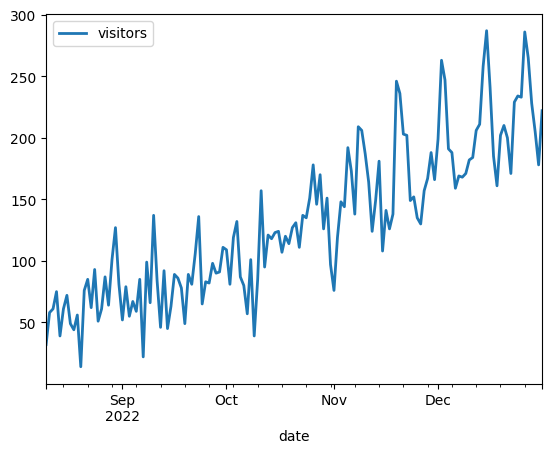

In [5]:
series.plot()

### 機械学習モデルの学習

Dartsのコードはscikit-learnと大きく変わらないことがメリット

In [6]:
# dartsの内部で補助ライブラリとしてpytorch-lightning(最新はlightning)を使用しているため
# !pip install pytorch-lightning

In [7]:
# モデルクラスの読み込み
from darts.models import ExponentialSmoothing

# モデルの学習 
model = ExponentialSmoothing()
model.fit(series)

The StatsForecast module could not be imported. To enable support for the AutoARIMA, AutoETS and Croston models, please consider installing it.
The `XGBoost` module could not be imported. To enable XGBoost support in Darts, follow the detailed instructions in the installation guide: https://github.com/unit8co/darts/blob/master/INSTALL.md
The `XGBoost` module could not be imported. To enable XGBoost support in Darts, follow the detailed instructions in the installation guide: https://github.com/unit8co/darts/blob/master/INSTALL.md


ExponentialSmoothing(trend=ModelMode.ADDITIVE, damped=False, seasonal=SeasonalityMode.ADDITIVE, seasonal_periods=None, error=add, random_errors=None, random_state=None, kwargs=None)

### モデルの評価

In [8]:
import matplotlib.pyplot as plt

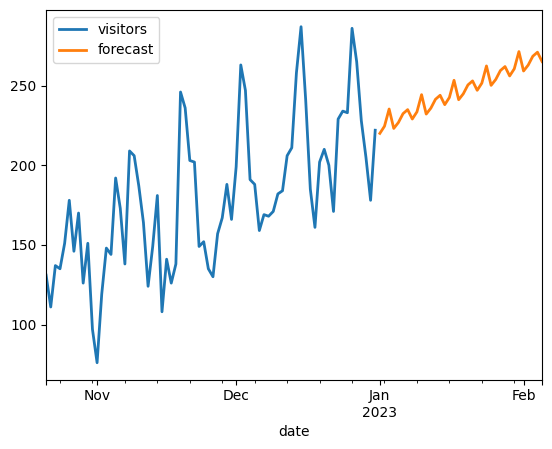

In [9]:
# 36期分(今回は日次データのため36日分)の未来を予測
prediction = model.predict(36)
# 後ろから72期間分だけ取り出す
series[-72:].plot()
# 予測結果を重ねて表示
prediction.plot(label="forecast")
# 凡例表示
plt.legend()

予測値(2023年1月～)は未来の値なので、正解が分からない...→ `クロスバリデーション`  
クロスバリデーションとは、データを学習用データとテスト用データに分割してモデルの評価を行うこと。  
一般的に、少し手間が必要だが、Dartsでは簡単に実行可能。  

次のコードで、最新の36日分のデータをテスト用テータ、残りを学習用データとして利用する。

<Axes: xlabel='date'>

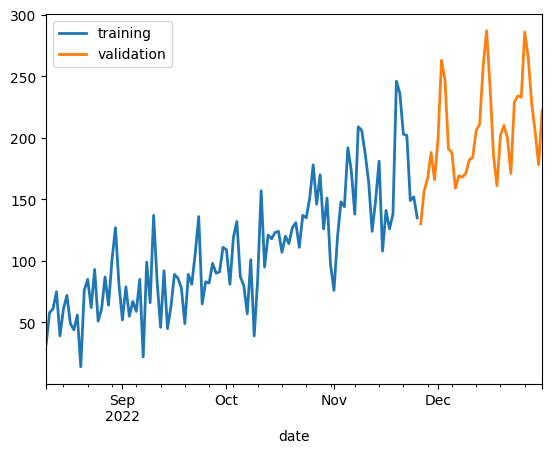

In [10]:
train, test = series[:-36], series[-36:]

train.plot(label="training")
test.plot(label="validation")

上図は元のデータを学習用とテスト用に分割したもので、オレンジ部分は2022年11月末～12月のデータ。

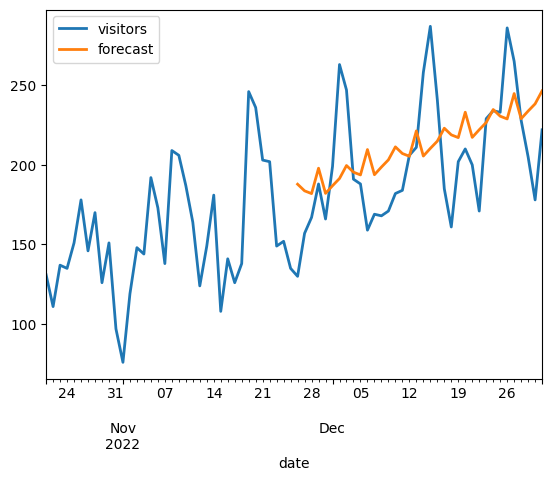

In [11]:
# 学習用データで学習して、予測値を算出後、重ねて表示
from darts.models import ExponentialSmoothing

model = ExponentialSmoothing()
model.fit(train)

prediction = model.predict(36)
series[-72:].plot()
prediction.plot(label="forecast")
plt.legend()

上図より、大まかなトレンドと変動は捉えられているが、周期的なスパイクまでは捉えられていないことが分かる。  
　トレンド：右肩上がりという傾向  
　変動：だいたいの山になっている箇所、谷になっている箇所のパターン  
　スパイク：山もしくは谷の上限/下限  

周期的なスパイクを捉えるためには、別の周期性を捉えるためのモデルを代わりに使ったり、複数のモデルを組み合わせて使う方法がある。  
そのような手法を使って改善していくために、現時点での精度を1つの指標で表してみる→`MAPE`

#### MAPE(Mean Absolute Percentage Error / 平均絶対パーセント誤差)

モデルの予測精度を評価するための指標の1つ。予測値と実測値の相対的な誤差の平均値を表す。  
予測の大きさに依存しないため、異なるスケールのデータを扱う場合に有用。  
(5%なら、予測は正解に比べておおむね5％程度ずれている、ということ)

In [12]:
from darts.metrics.metrics import mape

mape(prediction, test)

np.float64(13.539638423487148)

上記より、今回は正解に対して約13%程度ずれているという結果になった。

### モデルによる予測

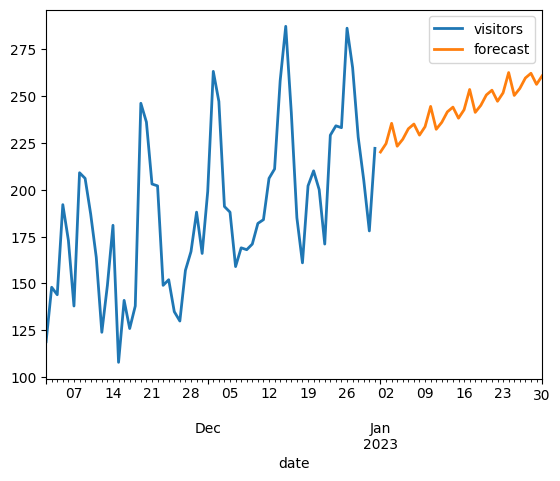

In [19]:
model = ExponentialSmoothing()
model.fit(series) 
prediction = model.predict(30)

series[-60:].plot()
prediction.plot(label="forecast")
plt.legend()

もっと精度を上げたい場合は、様々なモデルを試したり、平日休日の情報をモデルに組み込めるProphetを使ったりすることで、精度向上が望める。